# Прогнозный выбор целых подграфов

Все данные синтетические. Работа выполняется в отдельной ветке; эталон v2 не изменяется.

Найдём корень проекта. В Colab при отсутствии файлов клонируется только рабочая ветка; локально используются уже полученные исходники.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
while root != root.parent and not (root/'efc').exists():
    root = root.parent
if not (root/'efc').exists():
    import subprocess
    target = Path('/content/Forecast_Edge_Fog_Cloud')
    subprocess.run(['git','clone','--branch','night/fefc-v3','https://github.com/annfridreksen/Forecast_Edge_Fog_Cloud.git',str(target)],check=True)
    root=target
os.chdir(root)
sys.path.insert(0,str(root))
print('Рабочая папка:',root)


Рабочая папка: /home/runner/work/Forecast_Edge_Fog_Cloud/Forecast_Edge_Fog_Cloud


Что исследуем: работоспособность неизменённого v2 и подключение команд от демонстрационной сети. Облако не включается в кандидаты; это граница постановки, мотивированная прежним результатом НСКФ, не универсальное свойство облака.

In [2]:
from efc.placement.study import controls,neural_placement
from efc.placement.views import placement_plots
import json,pandas as pd
control,plans,audits=controls()
display(control)

,scenario,requested_method,effective_method,forecast_status,assignment,time_ms,status,checked
0,minimal,P,P,synthetic_control,"E,F,E",8.0,FEASIBLE_CERTIFIED,2
1,minimal,B,B,not_used,"F,F,F",4.0,FEASIBLE_CERTIFIED,6
2,deadline_filter,P,P,synthetic_control,"E,F,F",6.0,FEASIBLE_CERTIFIED,5
3,no_feasible,P,P,synthetic_control,,NaN,NO_PLAN_IN_CLASS,6


Посмотрим порядок реально проверенных назначений и оставшуюся границу. Ограниченный поиск не объявляется доказательством невозможности, а число проверок — временем исполнения.

In [3]:
print(json.dumps(audits['minimal_P'],ensure_ascii=False,indent=2,default=str))
assert plans['minimal_P']['plan']['makespan']=='1/125'
assert plans['minimal_B']['plan']['makespan']=='1/250'

{
  "checked_assignments": [
    [
      "E",
      "F",
      "E"
    ],
    [
      "F",
      "E",
      "E"
    ]
  ],
  "frontier": [
    {
      "bound": [
        "2",
        "2",
        "1"
      ],
      "prefix": [
        "E",
        "F",
        "F"
      ]
    },
    {
      "bound": [
        "2",
        "2",
        "1"
      ],
      "prefix": [
        "F",
        "E",
        "F"
      ]
    },
    {
      "bound": [
        "2",
        "2",
        "1"
      ],
      "prefix": [
        "F",
        "F"
      ]
    }
  ],
  "stop_reason": "ordinal_bound",
  "effective_method": "P"
}


Второй расчёт использует предсказания сети из тетради02. Если она ещё не запускалась, сначала получаем её результаты. Очереди Fog0/Fog1 взяты из временной точки той же среды; P и B получают одинаковый снимок.

In [4]:
if not Path('results/demo_network.json').exists():
    from efc.forecast.study import forecast_study
    forecast_study()
linked,payload=neural_placement()
display(linked)
print('Прогнозы:',payload['predictions'])
print('Ранги:',payload['ranks'])
print(payload['scope'])

,requested_method,effective_method,forecast_status,assignment,planned_ms,actual_ms,checked
0,P,P,external_neural,"F1,F0,F1",2888.5,2921.409673,2
1,B,B,not_used,"F1,F0,F0",2887.5,2920.409673,4


Прогнозы: {'F0': {'mean_ms': 2850.6593075625333, 'p95_ms': 2985.4262639500134}, 'F1': {'mean_ms': 327.37219660755034, 'p95_ms': 462.1391529950304}}
Ранги: {'F0': 2, 'F1': 1}
Forecast model trained on Fog requests, therefore this bridge uses two Fog nodes, a subset of allowed E/F devices. No extrapolation to untrained Edge hardware. Graph and message sizes are explicit synthetic additions; predictions supply ranks only, never block durations. Existing background is frozen; no new arrivals during this short graph execution.


Граф и диаграммы Ганта строятся из проверенных планов, не рисуются вручную по ожидаемому ответу. Синий/оранжевый цвет обозначает устройство целого подграфа.

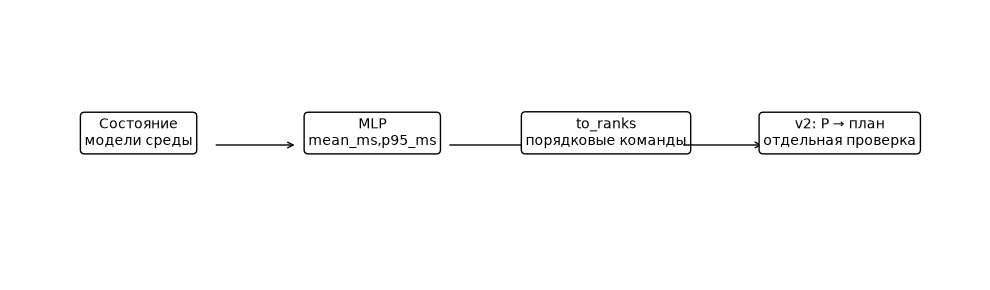

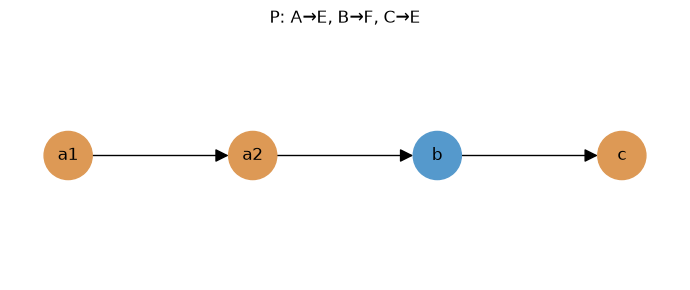

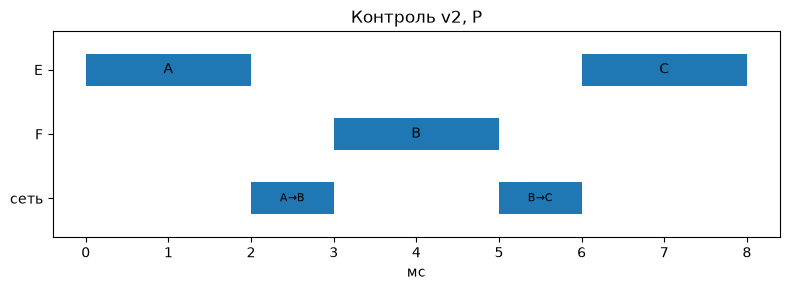

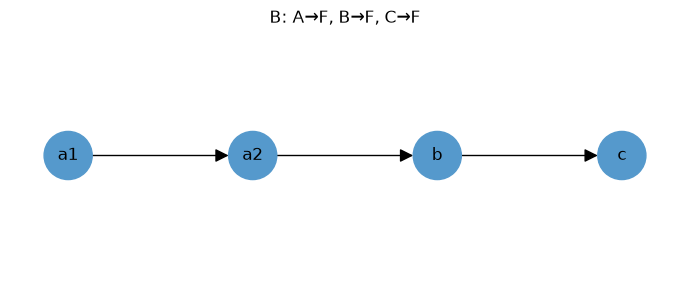

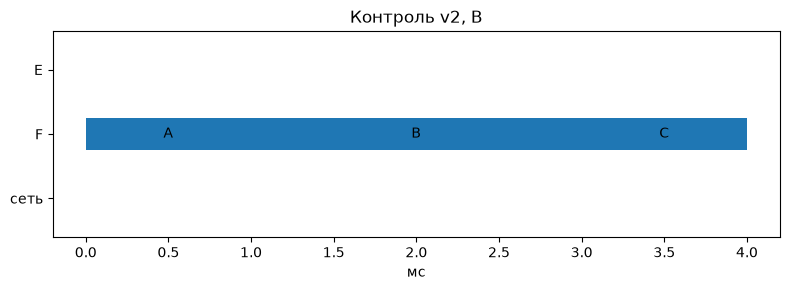

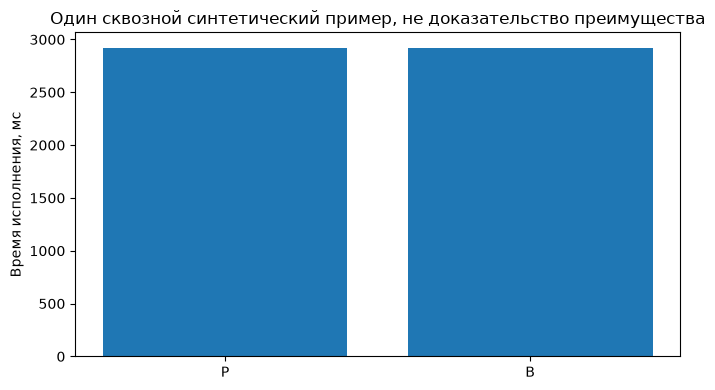

In [5]:
placement_plots(plans,payload)

Проверка: известные контрольные числа должны совпасть точно. Результат P/B сквозного примера сохраняется при любом знаке разности; преимущество по одному случаю не устанавливается.

In [6]:
assert list(control.time_ms.iloc[:3])==[8,4,6]
assert control.status.iloc[3]=='NO_PLAN_IN_CLASS'
assert len(linked)==2
assert all(x['violations']==[] for x in payload['replay'].values())
display(linked.rename(columns={'planned_ms':'план: статья = модель','actual_ms':'исполнение: статья = модель'}))
print('OK')

,requested_method,effective_method,forecast_status,assignment,план: статья = модель,исполнение: статья = модель,checked
0,P,P,external_neural,"F1,F0,F1",2888.5,2921.409673,2
1,B,B,not_used,"F1,F0,F0",2887.5,2920.409673,4


OK
